# 03 · Fusée et plume : du baril à la pompe

Les automobilistes en sont persuadés : quand le pétrole flambe, les prix à la pompe montent aussitôt, et quand il baisse, ils prennent leur temps. Les économistes appellent cela l'effet **« fusée et plume »** (*rockets and feathers*). Ce notebook le mesure sur vingt ans de données françaises.

**Questions**
1. De quoi est fait le prix d'un litre de gazole, et qu'est-ce qui l'a fait grimper en 2026 ?
2. La part qui revient au raffinage et à la distribution a-t-elle changé ?
3. Les prix montent-ils plus vite qu'ils ne baissent quand le Brent varie ?
4. Que s'est-il passé pendant la crise de 2026 ?

**Données**
- **Bulletin pétrolier européen** (Commission européenne, CC BY 4.0) : prix moyens hebdomadaires en France, avec et sans taxes, chaque lundi depuis 2005.
- **Brent daté** et **taux euro/dollar** (FRED, Réserve fédérale de Saint-Louis), quotidiens, convertis en euros par litre (159 litres par baril).
- L'historique des prix des stations (notebook 02), pour vérifier que le bulletin décrit bien les mêmes pompes.

Les deux premières sources sont collectées par le workflow quotidien sur la branche `data` (dossier `marches/`). Prix en **euros courants**. Les chiffres cités dans le texte sont recalculés et vérifiés par la dernière cellule.

In [1]:
from datetime import date
import json
import subprocess
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from carburants import analyse, marches, transmission

DONNEES = Path("../data")
FIGURES = Path("../rapports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)
chiffres = {}

pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_width_chars(140)

BLEU, ORANGE, AQUA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#8a5cd6"
TEXTE, TEXTE_2, GRILLE, FOND = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": FOND, "axes.facecolor": FOND, "savefig.facecolor": FOND,
    "axes.edgecolor": GRILLE, "axes.labelcolor": TEXTE_2, "axes.titlecolor": TEXTE,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.6,
    "xtick.color": TEXTE_2, "ytick.color": TEXTE_2, "font.size": 10,
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
})

def sauver(fig, nom):
    fig.savefig(FIGURES / f"{nom}.png")

def axe_annees(ax, pas=2):
    ax.xaxis.set_major_locator(mdates.YearLocator(pas))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

commit = subprocess.run(["git", "-C", str(DONNEES), "log", "-1", "--format=%h %ci"], capture_output=True, text=True).stdout.strip()
print("Branche data au commit :", commit or "inconnu")
print("Bulletin :", (DONNEES / "marches/bulletin_petrolier/source.txt").read_text().strip())

Branche data au commit : b3ec596 2026-10-19 14:28:46 +0000
Bulletin : https://energy.ec.europa.eu/document/download/906e60ca-8b6a-44e7-8589-652854d2fd3f_en?filename=Weekly_Oil_Bulletin_Prices_History_maticni_4web.xlsx


## Les données

Le bulletin donne, chaque lundi, le prix moyen national du gazole et du sans-plomb 95 avec et sans taxes. On lui associe le cours moyen du Brent sur les sept jours qui précèdent, en euros par litre.

Une correction s'impose pour 2022 : la **remise carburant de l'État** (18 centimes TTC du 1er avril au 31 août, 30 du 1er septembre au 15 novembre, 10 du 16 novembre au 31 décembre) est déduite des prix du bulletin. On la rajoute au prix hors taxes pour mesurer ce que facture la filière. La remise propre à TotalEnergies (septembre à décembre 2022) n'est pas corrigée : c'est un choix commercial, qui fait partie de la marge.

In [2]:
bulletin = marches.lire_bulletin((DONNEES / "marches/bulletin_petrolier/historique_prix.xlsx").read_bytes())
brent = transmission.brent_hebdo(pl.read_parquet(DONNEES / "marches/brent_change.parquet"))
hebdo = (
    bulletin.join(brent, on="date", how="inner")
    .with_columns(remise=transmission.remise_etat())
    .with_columns(
        marge_gazole=pl.col("gazole_ht") + pl.col("remise") - pl.col("brent_eur_litre"),
        marge_sp95=pl.col("sp95_ht") + pl.col("remise") - pl.col("brent_eur_litre"),
        taxes_gazole=pl.col("gazole_ttc") - pl.col("gazole_ht"),
    )
)
grille = pl.DataFrame({"date": pl.date_range(hebdo["date"].min(), hebdo["date"].max(), "1w", eager=True)})
manquantes = grille.join(hebdo, on="date", how="anti")["date"]
chiffres["semaines"], chiffres["semaines_manquantes"] = hebdo.height, manquantes.len()
chiffres["derniere_manquante"] = manquantes.max().year
print(f"{hebdo.height} semaines du {hebdo['date'].min()} au {hebdo['date'].max()}, {manquantes.len()} sans bulletin :")
print(", ".join(f"{d:%d/%m/%Y}" for d in manquantes))
hebdo.tail(3)

1088 semaines du 2005-01-03 au 2026-10-12, 49 sans bulletin :
28/03/2005, 31/10/2005, 26/12/2005, 02/01/2006, 17/04/2006, 25/12/2006, 01/01/2007, 09/04/2007, 24/12/2007, 31/12/2007, 24/03/2008, 22/12/2008, 29/12/2008, 13/04/2009, 28/12/2009, 05/04/2010, 01/11/2010, 27/12/2010, 25/04/2011, 15/08/2011, 26/12/2011, 02/01/2012, 09/04/2012, 24/12/2012, 31/12/2012, 23/12/2013, 30/12/2013, 21/04/2014, 22/12/2014, 29/12/2014, 06/04/2015, 21/12/2015, 28/12/2015, 28/03/2016, 26/12/2016, 17/04/2017, 25/12/2017, 02/04/2018, 24/12/2018, 31/12/2018, 22/04/2019, 23/12/2019, 30/12/2019, 13/04/2020, 28/12/2020, 04/01/2021, 05/04/2021, 27/12/2021, 18/04/2022


date,sp95_ht,sp95_ttc,gazole_ht,gazole_ttc,brent_usd_baril,brent_eur_litre,jours,remise,marge_gazole,marge_sp95,taxes_gazole
date,f64,f64,f64,f64,f64,f64,u32,f64,f64,f64,f64
2026-09-28,1.153783,2.21278,1.368025,2.37063,117.084,0.645257,5,0.0,0.722768,0.508526,1.002605
2026-10-05,1.152892,2.21171,1.3554,2.35548,120.034,0.667756,5,0.0,0.687644,0.485135,1.00008
2026-10-12,1.153317,2.21222,1.332708,2.32825,127.432,0.715093,5,0.0,0.617615,0.438223,0.995542


Il manque 49 bulletins, presque tous autour de Pâques et de Noël (et quelques autres jours fériés), jusqu'en 2022. Le modèle de la section 3 perd les semaines qui suivent chaque trou (il lui faut cinq semaines consécutives de variations) ; une variante comble ces trous par interpolation.

### Le bulletin et nos stations racontent-ils la même histoire ?

Le bulletin est une moyenne officielle ; nos données sont les prix de chaque station. On reconstruit la moyenne simple des stations chaque semaine (même méthode que le notebook 02) et on la compare au bulletin. Attention au calendrier : notre semaine du lundi au dimanche retient le dernier prix publié, c'est-à-dire le prix en vigueur à la fin de la semaine ; le bulletin daté du lundi suivant décrit les prix de ce même moment.

In [3]:
prix = analyse.charger_historique(DONNEES / "historique")
stations = (
    analyse.prix_hebdo(prix.filter(pl.col("carburant").is_in(["Gazole", "SP95"])))
    .group_by("carburant", "semaine").agg(moyenne=pl.col("prix").mean(), stations=pl.len())
    .filter(pl.col("stations") >= 500, pl.col("semaine") >= date(2007, 3, 5))
)
comparaison = (
    stations.pivot(on="carburant", index="semaine", values="moyenne")
    .with_columns(date=pl.col("semaine") + pl.duration(weeks=1))
    .join(bulletin, on="date")
    .drop_nulls(["Gazole", "SP95"])
    .with_columns(ecart_gazole=pl.col("Gazole") - pl.col("gazole_ttc"), ecart_sp95=pl.col("SP95") - pl.col("sp95_ttc"))
)
for carburant, nom in [("gazole", "Gazole"), ("sp95", "SP95")]:
    ecart = comparaison[f"ecart_{carburant}"]
    chiffres[f"correlation_{carburant}"] = np.corrcoef(comparaison[nom], comparaison[f"{carburant}_ttc"])[0, 1]
    variations = comparaison.select(pl.col(nom, f"{carburant}_ttc").diff()).drop_nulls()
    chiffres[f"correlation_variations_{carburant}"] = np.corrcoef(variations[nom], variations[f"{carburant}_ttc"])[0, 1]
    chiffres[f"ecart_stations_{carburant}"] = ecart.mean()
    chiffres[f"ecart_stations_{carburant}_p05"], chiffres[f"ecart_stations_{carburant}_p95"] = ecart.quantile(0.05), ecart.quantile(0.95)
chiffres["semaines_comparees"] = comparaison.height
print(f"{comparaison.height} semaines comparées")
comparaison.group_by(annee=pl.col("semaine").dt.year().cast(pl.Utf8)).agg(
    (pl.col("ecart_gazole", "ecart_sp95").mean() * 100).round(1)
).sort("annee").transpose(include_header=True, column_names="annee")

981 semaines comparées


column,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""ecart_gazole""",0.5,1.2,0.7,1.4,2.0,2.1,2.1,1.9,1.8,1.9,1.8,1.7,1.6,1.8,1.9,2.7,2.6,2.2,2.4,2.2
"""ecart_sp95""",1.4,2.1,1.6,1.9,2.0,2.7,2.5,2.1,2.1,2.2,2.1,2.2,2.0,2.3,2.2,3.1,2.1,1.6,2.1,1.2


Sur 981 semaines, la moyenne des stations et le bulletin évoluent ensemble : corrélation de 0,9997 pour le gazole (0,9994 pour le SP95), et encore 0,98 sur les variations d'une semaine à l'autre (0,96). La moyenne des stations est toutefois **1,8 centimes plus chère** pour le gazole (2,1 pour le SP95), un écart stable : entre 0,6 et 3,0 centimes neuf semaines sur dix. Notre hypothèse est une pondération par les volumes vendus dans le bulletin, alors que notre moyenne donne le même poids à une petite station de village et à un hypermarché qui vend beaucoup moins cher ; la méthode de calcul du bulletin n'est pas détaillée dans le fichier. La suite utilise le bulletin, qui offre le hors taxes et remonte à 2005.

## 1. De quoi est fait un litre de gazole

In [4]:
annuel = (
    hebdo.group_by(annee=pl.col("date").dt.year())
    .agg(pl.col("brent_eur_litre", "marge_gazole", "taxes_gazole", "remise", "gazole_ttc", "marge_sp95").mean(), semaines=pl.len())
    .sort("annee")
)
def annee(a, colonne):
    return annuel.filter(annee=a)[colonne].item()
for a in [2012, 2025, 2026]:
    chiffres[f"ttc_{a}"] = annee(a, "gazole_ttc")
    chiffres[f"brent_{a}"] = annee(a, "brent_eur_litre")
    chiffres[f"part_brent_{a}"] = annee(a, "brent_eur_litre") / annee(a, "gazole_ttc") * 100
    chiffres[f"part_taxes_{a}"] = annee(a, "taxes_gazole") / annee(a, "gazole_ttc") * 100
for poste in ["brent_eur_litre", "marge_gazole", "taxes_gazole"]:
    chiffres[f"hausse_2026_{poste}"] = annee(2026, poste) - annee(2025, poste)
chiffres["hausse_2026_ttc"] = annee(2026, "gazole_ttc") - annee(2025, "gazole_ttc")
annuel.with_columns(pl.exclude("annee", "semaines").round(3))

annee,brent_eur_litre,marge_gazole,taxes_gazole,remise,gazole_ttc,marge_sp95,semaines
i32,f64,f64,f64,f64,f64,f64,u32
2005,0.274,0.164,0.585,0.0,1.023,0.109,49
2006,0.327,0.159,0.594,0.0,1.079,0.12,49
2007,0.328,0.159,0.605,0.0,1.091,0.135,49
2008,0.421,0.221,0.637,0.0,1.279,0.115,49
2009,0.273,0.137,0.592,0.0,1.002,0.132,50
2010,0.374,0.153,0.615,0.0,1.143,0.142,49
2011,0.501,0.176,0.655,0.0,1.333,0.14,49
2012,0.546,0.192,0.659,0.0,1.397,0.16,49
2013,0.515,0.176,0.661,0.0,1.351,0.159,50


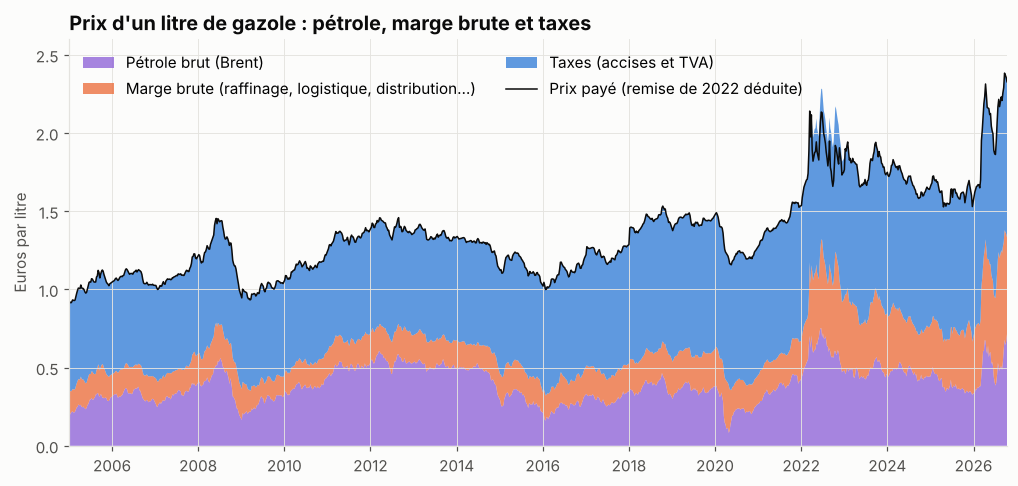

In [5]:
fig, ax = plt.subplots(figsize=(11, 4.8))
x = hebdo["date"]
couches = [hebdo["brent_eur_litre"], hebdo["marge_gazole"], hebdo["taxes_gazole"]]
ax.stackplot(x, *couches, colors=[VIOLET, ORANGE, BLEU], alpha=0.75, linewidth=0,
             labels=["Pétrole brut (Brent)", "Marge brute (raffinage, logistique, distribution...)", "Taxes (accises et TVA)"])
ax.plot(x, hebdo["gazole_ttc"], color=TEXTE, linewidth=1, label="Prix payé (remise de 2022 déduite)")
ax.set_ylabel("Euros par litre")
ax.set_ylim(0, 2.6)
ax.set_title("Prix d'un litre de gazole : pétrole, marge brute et taxes")
axe_annees(ax)
ax.legend(loc="upper left", frameon=False, ncols=2)
ax.set_xlim(x.min(), x.max())
sauver(fig, "11_decomposition_gazole")

En 2026, le Brent ne représente que **25 %** du prix moyen du gazole (0,51 € sur 2,04 €), contre 39 % en 2012, année où le baril valait pourtant un peu plus en euros (0,55 € par litre). Les taxes pèsent 46 % du prix, et la part « raffinage, transport, distribution » a grossi.

Entre 2025 et 2026 (moyennes de janvier à mi-octobre pour 2026), le gazole a pris 42 centimes : 12 viennent du Brent, 7 des taxes (la TVA augmente avec le prix) et **23 de l'écart entre le brut et la pompe**. Le pétrole n'explique donc qu'une petite partie de la flambée de 2026.

## 2. L'écart entre le baril et la pompe a doublé

On appelle ici **marge brute** l'écart entre le prix hors taxes et le coût du Brent. Ce n'est pas le bénéfice des distributeurs : elle paie le raffinage, le transport, le stockage, les biocarburants incorporés, les certificats d'économie d'énergie et la distribution. Mais son évolution dit où va l'argent.

Pointe de 2026 : 2026-08-31 0.748


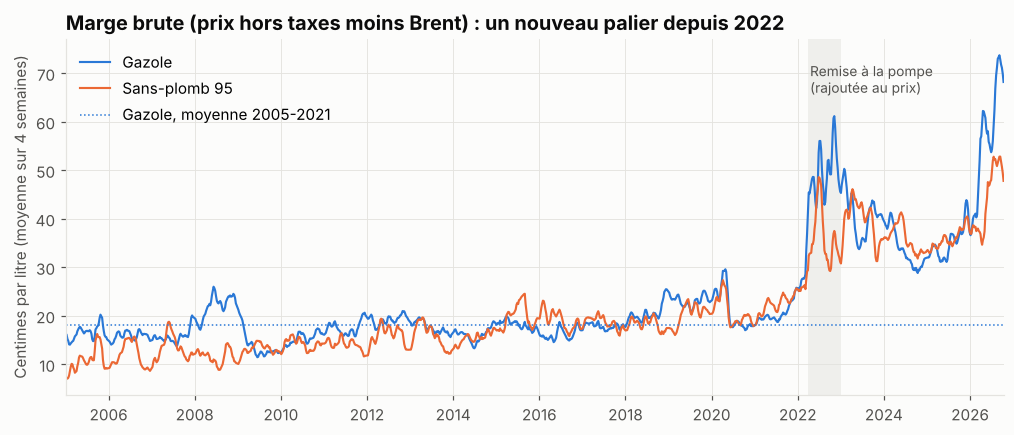

In [6]:
avant = hebdo.filter(pl.col("date").dt.year() <= 2021)
for carburant in ["gazole", "sp95"]:
    chiffres[f"marge_{carburant}_2005_2021"] = avant[f"marge_{carburant}"].mean()
    chiffres[f"marge_{carburant}_2023_2025"] = hebdo.filter(pl.col("date").dt.year().is_between(2023, 2025))[f"marge_{carburant}"].mean()
    chiffres[f"marge_{carburant}_2026"] = annee(2026, f"marge_{carburant}")  # janvier à mi-octobre
    chiffres[f"marge_{carburant}_2022"] = annee(2022, f"marge_{carburant}")
chiffres["marge_gazole_fevrier_2022"] = hebdo.filter(pl.col("date").is_between(date(2022, 1, 1), date(2022, 2, 21)))["marge_gazole"].mean()
pointe = hebdo.filter(pl.col("date").dt.year() == 2026).sort("marge_gazole").row(-1, named=True)
chiffres["marge_gazole_pointe"] = pointe["marge_gazole"]
print("Pointe de 2026 :", pointe["date"], round(pointe["marge_gazole"], 3))
fig, ax = plt.subplots(figsize=(11, 4.2))
for carburant, couleur, nom in [("gazole", BLEU, "Gazole"), ("sp95", ORANGE, "Sans-plomb 95")]:
    lisse = hebdo.select("date", pl.col(f"marge_{carburant}").rolling_mean(4, min_samples=2))
    ax.plot(lisse["date"], lisse[f"marge_{carburant}"] * 100, color=couleur, linewidth=1.4, label=nom)
ax.axhline(chiffres["marge_gazole_2005_2021"] * 100, color=BLEU, linestyle=":", linewidth=1, label="Gazole, moyenne 2005-2021")
ax.axvspan(date(2022, 4, 1), date(2022, 12, 31), color=GRILLE, alpha=0.5, linewidth=0)
ax.annotate("Remise à la pompe\n(rajoutée au prix)", (date(2022, 4, 15), 66), color=TEXTE_2, fontsize=9)
ax.set_ylabel("Centimes par litre (moyenne sur 4 semaines)")
ax.set_title("Marge brute (prix hors taxes moins Brent) : un nouveau palier depuis 2022")
axe_annees(ax)
ax.set_xlim(hebdo["date"].min(), hebdo["date"].max())
ax.legend(loc="upper left", frameon=False)
sauver(fig, "12_marge_brute")

De 2005 à 2021, l'écart entre le Brent et le gazole hors taxes tourne autour de **18 centimes** par litre (16 pour le SP95). Il commence à monter fin 2021 (27 centimes en moyenne en janvier et février 2022, avant l'invasion de l'Ukraine), puis change de palier : 45 centimes en 2022, 37 centimes en moyenne de 2023 à 2025 (37 pour le SP95), puis **58 centimes en 2026**, avec une pointe à 75 centimes à la fin de l'été.

Les deux crises touchent surtout le gazole : 45 centimes contre 34 pour le SP95 en 2022, 58 contre 44 en 2026. Entre les deux, de 2023 à 2025, l'essence et le gazole sont au même niveau, deux fois plus haut qu'avant 2021, ce qui évoque des coûts communs (transport, biocarburants, certificats d'économie d'énergie, distribution) autant que le raffinage. Le surcroît propre au gazole pendant les crises est compatible avec un raffinage du gazole sous tension en Europe, qui en importait une partie de Russie avant l'embargo de 2023 ; mais le bulletin ne permet pas de séparer raffinage et distribution. Il faudrait pour cela les prix de gros : les cotations européennes (Rotterdam) ne sont pas en accès libre, les cotations américaines (port de New York, publiées par la FRED) sont une piste pour une prochaine version.

## 3. Fusée et plume : les prix montent-ils plus vite qu'ils ne baissent ?

Comparer les hausses et les baisses à l'œil ne suffit pas : le prix réagit avec retard, et il rattrape progressivement son niveau d'équilibre. On utilise donc le modèle de référence de la littérature (Borenstein, Cameron et Gilbert, 1997), un **modèle à correction d'erreur asymétrique** :

$$\Delta p_t = \alpha + \sum_{i=0}^{4} \left(a^+_i \, \Delta c^+_{t-i} + a^-_i \, \Delta c^-_{t-i}\right) + \sum_{j=1}^{2} g_j \, \Delta p_{t-j} + \theta \left(p_{t-1} - \varphi \, c_{t-1} - f(t-1)\right) + \varepsilon_t$$

- $p$ est le prix hors taxes (remise de 2022 rajoutée), $c$ le Brent en euros par litre, $\Delta c^+$ et $\Delta c^-$ ses hausses et ses baisses d'une semaine à l'autre ;
- le dernier terme ramène le prix vers sa relation de long terme avec le Brent ($\varphi$ centimes par centime de Brent, plus une marge $f$ qui évolue lentement, estimée par une spline) ;
- s'il y a « fusée et plume », les $a^+$ sont plus grands que les $a^-$. Le test porte sur la somme des coefficients sur les cinq semaines : $\sum a^+_i = \sum a^-_i$.

Le modèle a un seul $\varphi$ et un seul $\theta$ : il impose qu'à long terme hausses et baisses se transmettent de la même façon. L'asymétrie qu'il peut mesurer est donc une asymétrie de **vitesse**.

On estime d'abord la relation de long terme, puis la dynamique, par moindres carrés avec des écarts-types robustes à l'autocorrélation (Newey-West, 4 semaines). La période principale est **2005-2021** : depuis 2022, la marge change de palier et la relation de long terme du gazole se déforme (voir les variantes plus bas). Le code est dans `carburants.transmission`, testé sur des données simulées dont on connaît l'asymétrie.

In [7]:
PERIODE = (date(2005, 1, 1), date(2021, 12, 31))
HORIZON = 26

def serie(carburant, debut=PERIODE[0], fin=PERIODE[1]):
    return hebdo.filter(pl.col("date").is_between(debut, fin)).select(
        "date", prix=pl.col(f"{carburant}_ht") + pl.col("remise"), cout="brent_eur_litre"
    )

modeles = {carburant: transmission.estimer(serie(carburant)) for carburant in ["gazole", "sp95"]}
reponses = {carburant: modele.asymetrie(HORIZON) for carburant, modele in modeles.items()}
coefs = pl.DataFrame({
    "coefficient": modeles["gazole"].noms,
    **{f"{carburant}{suffixe}": [round(fonction(modele, nom), 3) for nom in modele.noms]
       for carburant, modele in modeles.items()
       for suffixe, fonction in [("", transmission.Transmission.coef), (" (é.-t.)", transmission.Transmission.ecart_type)]},
})
for carburant, modele in modeles.items():
    chiffres[f"phi_{carburant}"] = modele.phi
    chiffres[f"rappel_{carburant}"] = -modele.coef("rappel") * 100
    chiffres[f"wald_{carburant}"] = modele.test_wald()[1]
    chiffres[f"wald0_{carburant}"] = modele.test_wald([0])[1]
    chiffres[f"observations_{carburant}"] = modele.observations
    chiffres[f"adf_{carburant}"] = modele.adf
    chiffres[f"demi_vie_{carburant}"] = np.log(0.5) / np.log(1 + modele.coef("rappel"))
    r = reponses[carburant]
    for h in [0, 1, 4, 12, 26]:
        for cle in ["hausse", "baisse", "ecart", "ecart_bas", "ecart_haut"]:
            chiffres[f"{cle}_{carburant}_{h}"] = r[cle][h]
    print(f"{carburant} : {modele.observations} semaines, R² = {modele.r2:.2f}, phi = {modele.phi:.2f}, "
          f"test d'égalité des sommes p = {chiffres[f'wald_{carburant}']:.3f}, au retard 0 p = {chiffres[f'wald0_{carburant}']:.3f}")
coefs

gazole : 659 semaines, R² = 0.68, phi = 1.09, test d'égalité des sommes p = 0.000, au retard 0 p = 0.001
sp95 : 659 semaines, R² = 0.55, phi = 0.97, test d'égalité des sommes p = 0.388, au retard 0 p = 0.558


coefficient,gazole,gazole (é.-t.),sp95,sp95 (é.-t.)
str,f64,f64,f64,f64
"""constante""",-0.002,0.001,0.0,0.001
"""hausse_0""",0.645,0.044,0.497,0.054
"""baisse_0""",0.403,0.048,0.444,0.055
"""hausse_1""",0.402,0.058,0.325,0.056
"""baisse_1""",0.233,0.059,0.328,0.05
"""hausse_2""",-0.033,0.055,0.032,0.052
"""baisse_2""",-0.04,0.044,0.065,0.053
"""hausse_3""",0.012,0.04,-0.019,0.053
"""baisse_3""",-0.045,0.056,0.104,0.062


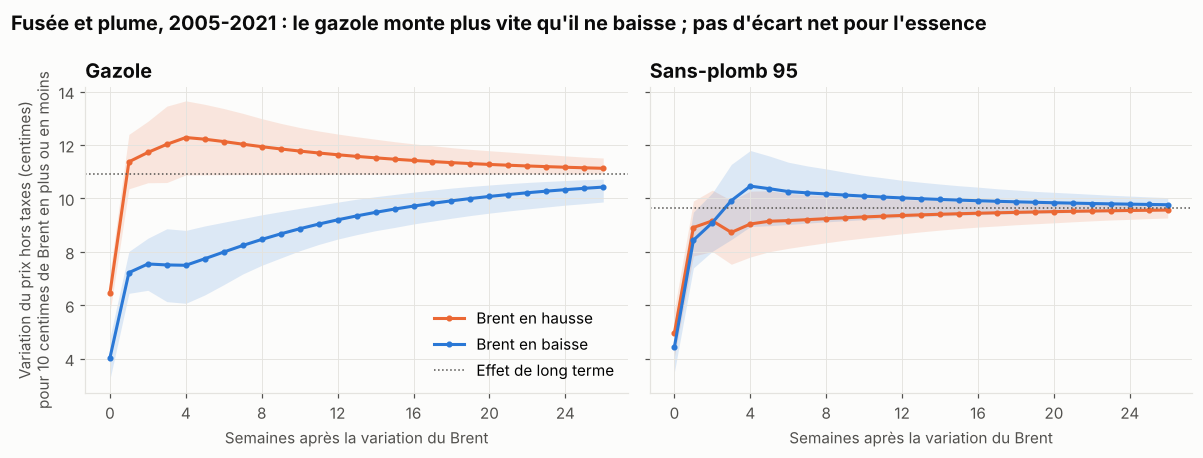

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
semaines = np.arange(HORIZON + 1)
for ax, (carburant, nom) in zip(axes, [("gazole", "Gazole"), ("sp95", "Sans-plomb 95")]):
    r = reponses[carburant]
    for sens, couleur, libelle in [("hausse", ORANGE, "Brent en hausse"), ("baisse", BLEU, "Brent en baisse")]:
        ax.fill_between(semaines, r[f"{sens}_bas"] * 10, r[f"{sens}_haut"] * 10, color=couleur, alpha=0.15, linewidth=0)
        ax.plot(semaines, r[sens] * 10, color=couleur, linewidth=2, marker="o", markersize=3, label=libelle)
    ax.axhline(modeles[carburant].phi * 10, color=TEXTE_2, linestyle=":", linewidth=1, label="Effet de long terme")
    ax.set_title(nom)
    ax.set_xlabel("Semaines après la variation du Brent")
    ax.set_xticks(range(0, HORIZON + 1, 4))
axes[0].set_ylabel("Variation du prix hors taxes (centimes)\npour 10 centimes de Brent en plus ou en moins")
axes[0].legend(loc="lower right", frameon=False)
fig.suptitle("Fusée et plume, 2005-2021 : le gazole monte plus vite qu'il ne baisse ; pas d'écart net pour l'essence",
             x=0.01, ha="left", fontsize=13, fontweight="bold", color=TEXTE)
fig.tight_layout()
sauver(fig, "13_fusee_et_plume")

Les résidus de la relation de long terme sont bien stationnaires, condition pour qu'un modèle à correction d'erreur ait un sens (statistique de Dickey-Fuller augmentée de −4,9 pour le gazole et −6,5 pour le SP95, bien en deçà de la valeur critique d'Engle et Granger, environ −3,3 à 5 % avec une constante seule).

**Le gazole monte en fusée et redescend en plume.** Quand le Brent gagne 10 centimes par litre, le gazole hors taxes a pris 11,4 centimes une semaine plus tard ; quand le Brent en perd 10, le gazole n'en a rendu que 7,2. L'écart, 4,1 centimes (intervalle à 90 % : 2,7 à 5,6), est encore de 4,8 centimes un mois après (2,6 à 7,1). Avec la TVA, il faut le multiplier par 1,2 à la pompe. Le test d'égalité des sommes de coefficients rejette nettement la symétrie (p = 0,0001).

L'écart se résorbe lentement : il vaut encore 2,4 centimes après trois mois (1,3 à 3,7) et 0,7 après six mois (0,3 à 1,6). C'est que l'ajustement vers l'équilibre est lent : chaque semaine, le prix comble environ 7 % de l'écart restant, soit une demi-vie de 9 semaines. À l'équilibre, un centime de Brent devient 1,09 centime de gazole hors taxes (0,97 pour le SP95), dans les deux sens par construction.

**Le sans-plomb 95 ne montre aucune asymétrie détectable** : 8,9 centimes à la hausse contre 8,4 à la baisse après une semaine, un écart qui n'est pas significatif (intervalle à 90 % : −1,4 à 2,2 ; p = 0,39). Ne pas détecter d'asymétrie ne prouve pas qu'il n'y en a aucune, mais si elle existe, elle est nettement plus faible que pour le gazole.

## 4. Les résultats tiennent-ils ?

On fait varier un choix à la fois : la période (avec 2022-2026, avec ou sans l'année 2022, ou 2023-2026 seule), le nombre de semaines de retard du Brent, la souplesse de la marge de long terme (constante, ou spline à 8 degrés de liberté) et le traitement des semaines sans bulletin. La colonne ADF donne la statistique de Dickey-Fuller des résidus de long terme : au-dessus d'environ −3,3, la cointégration n'est pas établie et le modèle à correction d'erreur est fragile.

In [9]:
VARIANTES = [
    ("Référence (2005-2021, 4 retards, spline 4)", {}),
    ("2005-2026", {"fin": date(2026, 12, 31)}),
    ("2005-2026 sans 2022", {"fin": date(2026, 12, 31), "exclure": (date(2022, 3, 1), date(2023, 1, 31))}),
    ("2023-2026 seulement", {"debut": date(2023, 2, 1), "fin": date(2026, 12, 31)}),
    ("Semaines manquantes comblées", {"combler_trous": True}),
    ("2 semaines de retard", {"retards_cout": 2}),
    ("6 semaines de retard", {"retards_cout": 6}),
    ("Marge de long terme constante", {"tendance_df": 0}),
    ("Spline à 8 degrés de liberté", {"tendance_df": 8}),
]
lignes = []
for nom, options in VARIANTES:
    options = dict(options)
    fin = options.pop("fin", PERIODE[1])
    debut = options.pop("debut", PERIODE[0])
    for carburant in ["gazole", "sp95"]:
        modele = transmission.estimer(serie(carburant, debut=debut, fin=fin), **options)
        r = modele.asymetrie(HORIZON)
        lignes.append({"variante": nom, "carburant": carburant, "semaines": modele.observations, "phi": round(modele.phi, 2),
                       "ADF": round(modele.adf, 1),
                       **{f"écart S{h} (c)": f"{r['ecart'][h] * 10:+.1f} [{r['ecart_bas'][h] * 10:+.1f} ; {r['ecart_haut'][h] * 10:+.1f}]" for h in [1, 4]},
                       "p (Wald)": round(modele.test_wald()[1], 3)})
        if nom != "2023-2026 seulement":
            chiffres[f"robustesse_min_ecart1_{carburant}"] = min(chiffres.get(f"robustesse_min_ecart1_{carburant}", np.inf), r["ecart"][1])
            chiffres[f"robustesse_min_bas1_{carburant}"] = min(chiffres.get(f"robustesse_min_bas1_{carburant}", np.inf), r["ecart_bas"][1])
        cle = {"2005-2026": "2026", "2005-2026 sans 2022": "sans_2022", "2023-2026 seulement": "2023_2026",
               "Marge de long terme constante": "constante", "Semaines manquantes comblées": "comble"}.get(nom)
        if cle:
            chiffres[f"phi_{carburant}_{cle}"] = modele.phi
            chiffres[f"wald_{carburant}_{cle}"] = modele.test_wald()[1]
            chiffres[f"adf_{carburant}_{cle}"] = modele.adf
            for h in [1, 4]:
                for k in ["ecart", "ecart_bas", "ecart_haut"]:
                    chiffres[f"{k}_{carburant}_{h}_{cle}"] = r[k][h]
robustesse = pl.DataFrame(lignes)
robustesse

variante,carburant,semaines,phi,ADF,écart S1 (c),écart S4 (c),p (Wald)
str,str,i64,f64,f64,str,str,f64
"""Référence (2005-2021, 4 retard…","""gazole""",659,1.09,-4.9,"""+4.1 [+2.7 ; +5.6]""","""+4.8 [+2.6 ; +7.1]""",0.0
"""Référence (2005-2021, 4 retard…","""sp95""",659,0.97,-6.5,"""+0.5 [-1.4 ; +2.2]""","""-1.4 [-3.6 ; +0.8]""",0.388
"""2005-2026""","""gazole""",898,1.31,-4.8,"""+5.9 [+1.8 ; +9.5]""","""+4.9 [+1.4 ; +8.6]""",0.023
"""2005-2026""","""sp95""",898,1.11,-6.3,"""+2.0 [-0.6 ; +4.5]""","""+0.4 [-2.0 ; +2.7]""",0.684
"""2005-2026 sans 2022""","""gazole""",851,1.17,-4.7,"""+3.7 [+0.9 ; +6.5]""","""+3.5 [-0.4 ; +7.4]""",0.124
"""2005-2026 sans 2022""","""sp95""",851,1.04,-5.6,"""+0.2 [-1.5 ; +1.9]""","""-0.1 [-2.4 ; +2.2]""",0.977
"""2023-2026 seulement""","""gazole""",188,1.28,-4.5,"""+0.7 [-3.6 ; +4.7]""","""-0.2 [-7.1 ; +5.7]""",0.981
"""2023-2026 seulement""","""sp95""",188,0.75,-4.0,"""+0.6 [-2.2 ; +3.3]""","""+1.8 [-0.9 ; +4.4]""",0.192
"""Semaines manquantes comblées""","""gazole""",881,1.09,-5.0,"""+3.2 [+1.4 ; +4.9]""","""+4.2 [+1.5 ; +6.8]""",0.007


Pour le gazole, l'écart après une semaine reste positif dans toutes les variantes sur 2005-2021 ou 2005-2026 (au moins 3,2 centimes pour 10 centimes de Brent, 4,1 dans la référence), et son intervalle à 90 % exclut zéro dans chacune (borne basse la plus faible : 0,9 centime). Combler les semaines sans bulletin le ramène à 3,2 centimes (1,4 à 4,9).

Le résultat est le moins net quand on ajoute 2023-2026 en retirant 2022 des deux étapes : l'écart après un mois n'est plus significatif et le test sur la somme des coefficients ne rejette plus la symétrie (p = 0,12). Sur 2023-2026 seulement, le modèle ne détecte aucune asymétrie (p = 0,98), mais avec moins de quatre ans de données les intervalles sont très larges. Pour le SP95, aucune variante ne trouve d'asymétrie significative.

Avec une marge de long terme constante, la cointégration est à la limite (ADF de −3,5 pour le gazole) : c'est ce qui justifie la spline, qui laisse la marge dériver lentement et rend les résidus nettement stationnaires.

In [10]:
# La relation de long terme a-t-elle changé après février 2022 ? Interaction du Brent avec une indicatrice
import statsmodels.api as sm
from patsy import dmatrix

def phi_avant_apres(carburant, debut=date(2005, 1, 1), fin=date(2026, 12, 31), rupture=date(2022, 3, 1)):
    x = serie(carburant, debut, fin).drop_nulls()
    annees = (x["date"] - x["date"].min()).dt.total_days().to_numpy() / 365.25
    apres = (x["date"] >= rupture).to_numpy().astype(float)
    tendance = np.asarray(dmatrix("bs(t, df=4, include_intercept=True) - 1", {"t": annees}))
    cout = x["cout"].to_numpy()
    resultat = sm.OLS(x["prix"].to_numpy(), np.column_stack([tendance, cout, cout * apres])).fit()
    return resultat.params[-2], resultat.params[-2] + resultat.params[-1]

for carburant in ["gazole", "sp95"]:
    chiffres[f"phi_{carburant}_avant_2022"], chiffres[f"phi_{carburant}_apres_2022"] = phi_avant_apres(carburant)
    chiffres[f"phi_{carburant}_apres_2022_sans_2026"] = phi_avant_apres(carburant, fin=date(2025, 12, 31))[1]
pl.DataFrame({"carburant": ["gazole", "sp95"],
              **{nom: [round(chiffres[f"phi_{c}_{nom}"], 2) for c in ["gazole", "sp95"]]
                 for nom in ["avant_2022", "apres_2022", "apres_2022_sans_2026"]}})

carburant,avant_2022,apres_2022,apres_2022_sans_2026
str,f64,f64,f64
"""gazole""",1.14,1.42,1.45
"""sp95""",0.96,1.19,1.21


La relation de long terme se déforme aussi depuis 2022. En laissant $\varphi$ changer en mars 2022 (estimation sur 2005-2026), un centime de Brent devient 1,14 centime de gazole hors taxes avant, et 1,42 après (0,96 et 1,19 pour le SP95). Ce n'est pas un effet de la seule année 2026 : sans elle, on trouve 1,45 pour le gazole. Depuis 2022, quand le pétrole monte, l'écart entre le brut et la pompe a tendance à monter avec lui. Ces valeurs dépendent toutefois de la façon de modéliser la marge de long terme, et sont à prendre comme des ordres de grandeur.

## 5. La crise de 2026, semaine par semaine

In [11]:
crise = hebdo.filter(pl.col("date") >= date(2025, 12, 1))
DEBUT_HAUSSE, SOMMET, CREUX, FIN_ETE = date(2026, 3, 2), date(2026, 4, 13), date(2026, 7, 6), date(2026, 8, 31)
FIN = crise["date"].max()
def le(jour, colonne):
    return crise.filter(date=jour)[colonne].item()
for phase, (debut, fin) in {"hausse": (DEBUT_HAUSSE, SOMMET), "baisse": (SOMMET, CREUX), "automne": (FIN_ETE, FIN)}.items():
    chiffres[f"crise_{phase}_brent"] = le(fin, "brent_eur_litre") - le(debut, "brent_eur_litre")
    chiffres[f"crise_{phase}_gazole"] = le(fin, "gazole_ht") - le(debut, "gazole_ht")
    chiffres[f"crise_{phase}_semaines"] = (fin - debut).days / 7
for jour, nom in [(DEBUT_HAUSSE, "debut"), (SOMMET, "sommet"), (CREUX, "creux"), (FIN_ETE, "fin_ete"), (FIN, "fin")]:
    chiffres[f"crise_marge_{nom}"] = le(jour, "marge_gazole")
print("Dernière semaine :", FIN)
crise.select("date", "brent_usd_baril", "brent_eur_litre", "gazole_ht", "marge_gazole").with_columns(pl.exclude("date").round(3))

Dernière semaine : 2026-10-12


date,brent_usd_baril,brent_eur_litre,gazole_ht,marge_gazole
date,f64,f64,f64,f64
2025-12-01,64.425,0.35,0.775,0.425
2025-12-08,63.982,0.346,0.751,0.405
2025-12-15,62.604,0.337,0.725,0.388
2025-12-22,60.826,0.326,0.666,0.34
2025-12-29,63.207,0.338,0.691,0.353
2026-01-05,62.182,0.333,0.717,0.384
2026-01-12,62.926,0.339,0.745,0.406
2026-01-19,66.996,0.362,0.759,0.397
2026-01-26,67.005,0.359,0.775,0.416


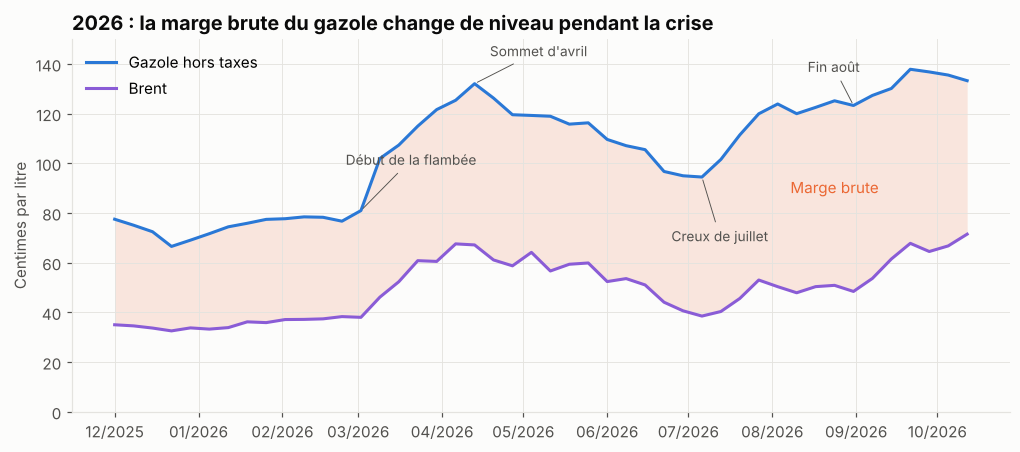

In [12]:
fig, ax = plt.subplots(figsize=(11, 4.4))
ax.fill_between(crise["date"], crise["brent_eur_litre"] * 100, crise["gazole_ht"] * 100, color=ORANGE, alpha=0.15, linewidth=0)
ax.plot(crise["date"], crise["gazole_ht"] * 100, color=BLEU, linewidth=2, label="Gazole hors taxes")
ax.plot(crise["date"], crise["brent_eur_litre"] * 100, color=VIOLET, linewidth=2, label="Brent")
for jour, texte, decalage in [(DEBUT_HAUSSE, "Début de la flambée", (-10, 30)), (SOMMET, "Sommet d'avril", (10, 18)), (CREUX, "Creux de juillet", (-20, -42)),
                              (FIN_ETE, "Fin août", (-30, 22))]:
    ax.annotate(texte, (jour, le(jour, "gazole_ht") * 100), xytext=decalage, textcoords="offset points", fontsize=9,
                color=TEXTE_2, arrowprops={"arrowstyle": "-", "color": TEXTE_2, "linewidth": 0.6})
milieu = crise.filter(date=date(2026, 8, 24)).row(0, named=True)
ax.annotate("Marge brute", (milieu["date"], (milieu["brent_eur_litre"] + milieu["gazole_ht"]) / 2 * 100), ha="center", color=ORANGE, fontsize=10)
ax.set_ylabel("Centimes par litre")
ax.set_ylim(0, 150)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
ax.set_title("2026 : la marge brute du gazole change de niveau pendant la crise")
ax.legend(loc="upper left", frameon=False)
sauver(fig, "14_crise_2026")

Du début mars à la mi-avril (6 semaines), le Brent prend 29 centimes par litre et le gazole hors taxes **51**. De la mi-avril au début juillet (12 semaines), le Brent rend tout ce qu'il avait pris (29 centimes), le gazole seulement 38. La marge brute passe ainsi de 43 centimes avant la crise à 65 au sommet, et reste à 56 au creux de juillet, loin de son niveau d'avant. Elle remonte ensuite jusqu'à 75 centimes fin août.

L'automne montre le mouvement inverse : de fin août à la mi-octobre, le Brent reprend 23 centimes, mais le gazole hors taxes seulement +10, et la marge redescend à 62 centimes. La marge brute absorbe donc une partie des chocs dans les deux sens.

Plutôt qu'un effet fusée et plume amplifié, 2026 ressemble à un **changement de niveau** de la marge brute du gazole, compatible avec un raffinage du gazole sous tension. Le modèle estimé sur 2023-2026 seulement ne détecte d'ailleurs pas d'asymétrie (p = 0,98), mais quatre années, dont une de crise, laissent beaucoup d'incertitude. Le bulletin ne dit pas quelle part de la marge revient aux raffineurs et quelle part aux distributeurs.

## Limites

- **Le Brent n'est pas le coût d'achat des stations.** Celles-ci achètent du gazole et de l'essence raffinés, dont le prix de gros (Rotterdam) peut s'écarter du brut. L'asymétrie mesurée ici couvre toute la chaîne, du baril à la pompe ; on ne peut pas dire si elle naît au raffinage ou à la distribution. Les prix de gros américains publiés par la FRED permettraient un premier découpage.
- **Moyenne nationale** : le bulletin est une moyenne pondérée. Certaines stations répercutent sans doute plus vite que d'autres ; c'est l'objet de l'étape suivante, station par station.
- **Données hebdomadaires** : la dynamique d'un jour à l'autre est invisible. Les semaines sans bulletin (Pâques et Noël) font perdre les semaines qui les suivent : 659 semaines sur 2005-2021 au lieu d'environ 880 ; les combler par interpolation ne change pas les conclusions.
- **Remise de TotalEnergies en 2022** : non corrigée, elle abaisse la marge moyenne de septembre à décembre 2022. Elle ne touche pas la période de référence (2005-2021), mais pèse sur les variantes qui vont jusqu'en 2026 ; la variante qui retire 2022 des deux étapes de l'estimation en tient compte.
- **Incertitude de la première étape** : les intervalles tiennent compte de l'incertitude sur la dynamique, pas sur la relation de long terme ($\varphi$ et la spline), qui est traitée comme connue.
- **Euros courants** : les marges ne sont pas corrigées de l'inflation, qui explique une partie de leur lente hausse avant 2022, mais pas le saut de 2022.

## À retenir

- **Le pétrole ne pèse que 25 % du prix du gazole en 2026**, contre 39 % en 2012 à baril comparable. Les taxes en font 46 %.
- **L'écart entre le baril et la pompe a changé de palier** : environ 18 centimes par litre de gazole jusqu'en 2021, 37 de 2023 à 2025 et 58 en 2026. Il explique la plus grande partie de la hausse de 2026.
- **Fusée et plume, oui pour le gazole** : sur 2005-2021, pour 10 centimes de Brent, le gazole hors taxes a monté de 11,4 centimes une semaine plus tard, mais n'a baissé que de 7,2. L'écart se résorbe lentement (demi-vie d'environ 9 semaines) et se retrouve dans toutes les variantes sur 2005-2021 ou 2005-2026.
- **Rien de détectable pour l'essence** : les réactions du SP95 aux hausses et aux baisses ne se distinguent pas.
- **2026 est d'abord un changement de niveau** de la marge brute du gazole, qui absorbe ensuite une partie des chocs dans les deux sens.
- Prochaine étape : passer de la moyenne nationale aux stations, et mesurer ce qui fait varier les prix de l'une à l'autre (concurrence locale, enseigne, autoroute).

In [13]:
# Vérification : les chiffres cités dans le texte ci-dessus correspondent aux calculs de ce notebook.
# Ils sont aussi exportés pour le site.
CHIFFRES_JSON = Path('../rapports/chiffres_03.json')
CHIFFRES_JSON.write_text(json.dumps({k: round(float(v), 6) for k, v in sorted(chiffres.items())}, indent=1) + "\n")
CITES = {
 "semaines_manquantes": [
  49.0,
  0.5
 ],
 "derniere_manquante": [
  2022.0,
  0.5
 ],
 "semaines_comparees": [
  981.0,
  0.5
 ],
 "correlation_gazole": [
  0.999742,
  5e-05
 ],
 "correlation_sp95": [
  0.999413,
  5e-05
 ],
 "correlation_variations_gazole": [
  0.975973,
  0.005
 ],
 "correlation_variations_sp95": [
  0.962916,
  0.005
 ],
 "ecart_stations_gazole": [
  0.018409,
  0.0005
 ],
 "ecart_stations_sp95": [
  0.021036,
  0.0005
 ],
 "ecart_stations_gazole_p05": [
  0.006221,
  0.0005
 ],
 "ecart_stations_gazole_p95": [
  0.029981,
  0.0005
 ],
 "part_brent_2026": [
  25.091402,
  0.5
 ],
 "brent_2026": [
  0.51109,
  0.005
 ],
 "ttc_2026": [
  2.036913,
  0.005
 ],
 "part_brent_2012": [
  39.093686,
  0.5
 ],
 "brent_2012": [
  0.54609,
  0.005
 ],
 "part_taxes_2026": [
  46.491215,
  0.5
 ],
 "hausse_2026_ttc": [
  0.418351,
  0.005
 ],
 "hausse_2026_brent_eur_litre": [
  0.124186,
  0.005
 ],
 "hausse_2026_taxes_gazole": [
  0.068024,
  0.005
 ],
 "hausse_2026_marge_gazole": [
  0.226141,
  0.005
 ],
 "marge_gazole_2005_2021": [
  0.18076,
  0.005
 ],
 "marge_sp95_2005_2021": [
  0.162764,
  0.005
 ],
 "marge_gazole_fevrier_2022": [
  0.26909,
  0.005
 ],
 "marge_gazole_2022": [
  0.451615,
  0.005
 ],
 "marge_gazole_2023_2025": [
  0.365504,
  0.005
 ],
 "marge_sp95_2023_2025": [
  0.371699,
  0.005
 ],
 "marge_gazole_2026": [
  0.578837,
  0.005
 ],
 "marge_gazole_pointe": [
  0.748431,
  0.005
 ],
 "marge_sp95_2022": [
  0.339704,
  0.005
 ],
 "marge_sp95_2026": [
  0.444381,
  0.005
 ],
 "adf_gazole": [
  -4.929319,
  0.05
 ],
 "adf_sp95": [
  -6.501086,
  0.05
 ],
 "hausse_gazole_1": [
  1.137041,
  0.005
 ],
 "baisse_gazole_1": [
  0.722124,
  0.005
 ],
 "ecart_gazole_1": [
  0.414918,
  0.005
 ],
 "ecart_bas_gazole_1": [
  0.272513,
  0.005
 ],
 "ecart_haut_gazole_1": [
  0.563969,
  0.005
 ],
 "ecart_gazole_4": [
  0.478357,
  0.005
 ],
 "ecart_bas_gazole_4": [
  0.255745,
  0.005
 ],
 "ecart_haut_gazole_4": [
  0.705284,
  0.005
 ],
 "wald_gazole": [
  0.000117,
  5e-05
 ],
 "ecart_gazole_12": [
  0.243685,
  0.005
 ],
 "ecart_bas_gazole_12": [
  0.130482,
  0.005
 ],
 "ecart_haut_gazole_12": [
  0.371766,
  0.005
 ],
 "ecart_gazole_26": [
  0.070347,
  0.005
 ],
 "ecart_bas_gazole_26": [
  0.025653,
  0.005
 ],
 "ecart_haut_gazole_26": [
  0.159144,
  0.005
 ],
 "rappel_gazole": [
  7.233356,
  0.5
 ],
 "demi_vie_gazole": [
  9.23174,
  0.5
 ],
 "phi_gazole": [
  1.092161,
  0.005
 ],
 "phi_sp95": [
  0.965331,
  0.005
 ],
 "hausse_sp95_1": [
  0.890973,
  0.005
 ],
 "baisse_sp95_1": [
  0.84335,
  0.005
 ],
 "ecart_bas_sp95_1": [
  -0.135992,
  0.005
 ],
 "ecart_haut_sp95_1": [
  0.220183,
  0.005
 ],
 "wald_sp95": [
  0.387872,
  0.005
 ],
 "robustesse_min_ecart1_gazole": [
  0.32147,
  0.005
 ],
 "robustesse_min_bas1_gazole": [
  0.094989,
  0.005
 ],
 "ecart_gazole_1_comble": [
  0.32147,
  0.005
 ],
 "ecart_bas_gazole_1_comble": [
  0.135237,
  0.005
 ],
 "ecart_haut_gazole_1_comble": [
  0.492648,
  0.005
 ],
 "wald_gazole_sans_2022": [
  0.124313,
  0.005
 ],
 "wald_gazole_2023_2026": [
  0.98071,
  0.005
 ],
 "adf_gazole_constante": [
  -3.505262,
  0.05
 ],
 "phi_gazole_avant_2022": [
  1.136947,
  0.005
 ],
 "phi_gazole_apres_2022": [
  1.419695,
  0.005
 ],
 "phi_sp95_avant_2022": [
  0.962237,
  0.005
 ],
 "phi_sp95_apres_2022": [
  1.19155,
  0.005
 ],
 "phi_gazole_apres_2022_sans_2026": [
  1.45188,
  0.005
 ],
 "crise_hausse_semaines": [
  6.0,
  0.5
 ],
 "crise_hausse_brent": [
  0.291455,
  0.005
 ],
 "crise_hausse_gazole": [
  0.5108,
  0.005
 ],
 "crise_baisse_semaines": [
  12.0,
  0.5
 ],
 "crise_baisse_brent": [
  -0.286392,
  0.005
 ],
 "crise_baisse_gazole": [
  -0.375758,
  0.005
 ],
 "crise_marge_debut": [
  0.429667,
  0.005
 ],
 "crise_marge_sommet": [
  0.649012,
  0.005
 ],
 "crise_marge_creux": [
  0.559646,
  0.005
 ],
 "crise_marge_fin_ete": [
  0.748431,
  0.005
 ],
 "crise_automne_brent": [
  0.230566,
  0.005
 ],
 "crise_automne_gazole": [
  0.09975,
  0.005
 ],
 "crise_marge_fin": [
  0.617615,
  0.005
 ],
 "observations_gazole": [
  659.0,
  0.5
 ]
}
ecarts_cites = {cle: (valeur, chiffres.get(cle)) for cle, (valeur, tolerance) in CITES.items()
                if chiffres.get(cle) is None or not abs(chiffres[cle] - valeur) <= tolerance}
assert not ecarts_cites, f"Chiffres du texte à mettre à jour : {ecarts_cites}"
print(f"{len(CITES)} chiffres cités, tous conformes aux calculs")

84 chiffres cités, tous conformes aux calculs
